# 13 · Same crack, phone camera app vs. VisionCrack app

Question: *is the guided capture needed? What happens if an inspector just takes an ordinary photo of the label?*
This notebook answers that with the crack and label of notebooks 11–12:

* **Same:** crack, phone (iPhone 15 Pro Max), measuring point rule (P3, 7–9 mm above the label frame), and the **same code and the
  same five options** as notebook 12.
* **Different:** how the photo is taken, and the **label placement** (§0): the camera-app photos were taken two days later with the label
  stuck on again at another spot of the crack. GT 0.45 mm was read at the app-day spot, so the error against GT is **indicative only** for
  the camera-app photos. The main comparison is the **spread** between photos, which needs no GT.

| | VisionCrack app (notebooks 11–12) | Phone camera app (this notebook) |
|---|---|---|
| Lens | always the main (1×) back camera | the phone picks: ultra-wide (macro) when close, main lens when farther |
| Distance | fixed: the label must fill the on-screen guide (each side ≥ 95 %) | free |
| Rotation | captured only if the label is within 2° | free |
| Focus / exposure | waits until the phone is still, then locks focus and exposure on the label | automatic |
| File | JPEG | HEIC (the camera app's default), shared here as PNG |
| Rejected photos | photos outside the gates are never saved | every photo is kept: **all 21 are reported here** |

The 21 photos were taken in **7 sets of 3** consecutive shots; within a set the phone was held the same way.

| | |
|---|---|
| **Inputs** | `data/raw/phone/IMG_*.png` (21 photos, camera app; converted from HEIC with ffmpeg, EXIF and GPS removed), `data/raw/images/VisionCrack_*.JPG` (10 photos, app) |
| **Outputs** | `results/figures/camera_app_label_position.png`, `results/tables/camera_app_capture.csv`, `camera_app_widths.csv`, `camera_app_summary.csv`, `camera_app_sets.csv`; `results/figures/camera_app_photos.png`, `camera_app_closeups.png`, `camera_app_result.png`, `camera_app_why.png` |
| **Runtime** | ~1 min |

In [ ]:
%matplotlib inline
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
import visioncrack as vc
from visioncrack import io, field
from visioncrack.constants import LABEL_WIDTH_MM, ROTATION_MAX_DEG
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

app_files = sorted((io.data_dir() / 'images').glob('VisionCrack_*.JPG'))
cam_files = sorted((io.data_dir() / 'phone').glob('IMG_*.png'))
assert len(app_files) == 10 and len(cam_files) == 21, (len(app_files), len(cam_files))
APP = [f'VisionCrack {i + 1}' for i in range(10)]
CAM = [f'Camera {i + 1}' for i in range(21)]
SET = np.arange(21) // 3 + 1                       # 7 sets of 3 consecutive photos

POINT_MM = (7.0, 9.0)      # measuring point P3, as in notebooks 11–12
GT_MM = 0.45
OPTIONS = {                # identical to notebook 12
    'middle row':           dict(rule='subpixel', scale='barcode', stat='middle'),
    'median':               dict(rule='subpixel', scale='barcode', stat='median'),
    'mean':                 dict(rule='subpixel', scale='barcode', stat='mean'),
    'Table 1 rule, > 2 px': dict(rule='paper', scale='label', stat='clipped', min_run=2),
    'Table 1 rule, > 6 px': dict(rule='paper', scale='label', stat='clipped', min_run=6),
}

def point(r, kw):
    return field.point_values(r, points=(POINT_MM,), **kw)[0] if np.isfinite(r.scale) else np.nan

def crack_px(r):
    # sub-pixel crack width in pixels at P3 (median of the rows)
    if not np.isfinite(r.scale):
        return np.nan
    m = (r.rows_y_mm >= POINT_MM[0]) & (r.rows_y_mm < POINT_MM[1])
    return float(np.nanmedian(r.rows_mm[m] / r.scale))

# Lens of each camera-app photo, read from the EXIF focal length of the original HEIC files
# (2.22 mm = ultra-wide, 6.77 mm = main 1×). The shared PNGs carry no EXIF, so it is listed here:
# sets 2 and 5 were taken with the main lens, the other sets with the ultra-wide lens.
MAIN_LENS_SETS = {2, 5}
LENS = {f.stem: ('main (1×)' if s in MAIN_LENS_SETS else 'ultra-wide') for f, s in zip(cam_files, SET)}

def lens(path):
    return LENS[path.stem]

rs_app = [field.measure_field(f) for f in app_files]
rs_cam = [field.measure_field(f) for f in cam_files]
V = pd.concat([
    pd.DataFrame({k: [point(r, kw) for r in rs] for k, kw in OPTIONS.items()}, index=names).assign(capture=cap)
    for rs, names, cap in [(rs_app, APP, 'VisionCrack app'), (rs_cam, CAM, 'camera app')]])
print('measured:', V.groupby('capture')['median'].apply(lambda s: f'{s.notna().sum()}/{len(s)}').to_dict())

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


measured: {'VisionCrack app': '10/10', 'camera app': '17/21'}


## 0 · Label placement on the two days

Same crop around the label in both sets (24 mm wide, frame top at 0). The crack crosses the label at a different place, and the
camera-app label is an opaque print (the crack does not show through it). P3 is therefore a different 2-mm piece of the same crack.

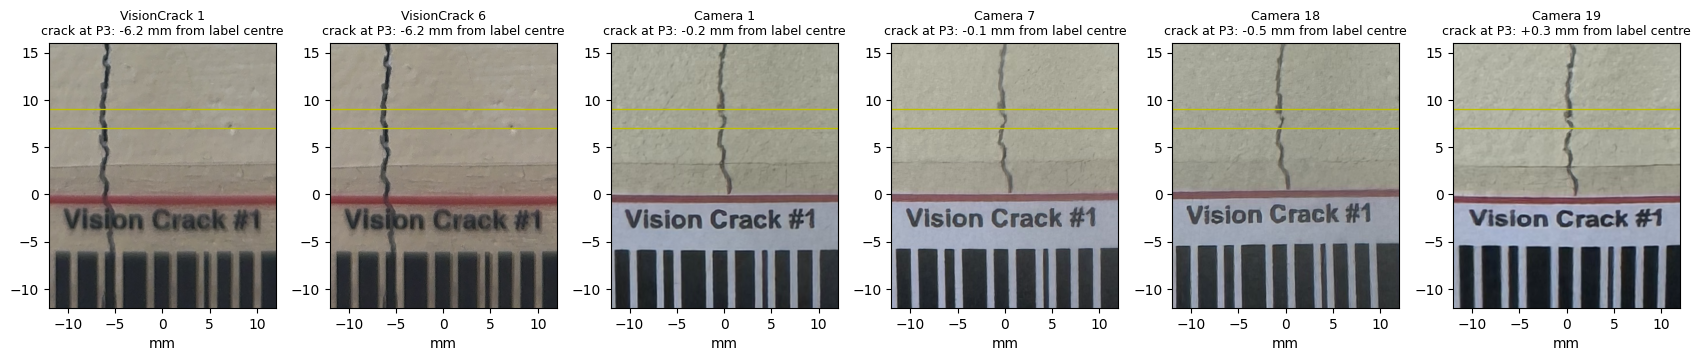

crack position at P3 from the label centre: app -6.3 ± 0.1 mm, camera app -0.4 ± 0.8 mm


In [ ]:
def label_crop(path, r):
    img = vc.read_rgb(path)
    (cx, cy), (w, h), _ = field.find_red_label(img); W, H = max(w, h), min(w, h)
    rot = field.derotate(img, r.angle_deg, (cx, cy)); g = field.grey(rot); top = int(cy - H / 2); s = r.scale
    y0, y1 = int(top - field.BAND_MM[1] / s), int(top - field.BAND_MM[0] / s)
    _, xs = field.crack_widths(g, int(cx - W / 2), int(cx + W / 2), y0, y1)
    m = (r.rows_y_mm >= POINT_MM[0]) & (r.rows_y_mm < POINT_MM[1])
    off = (np.median(xs[m]) - cx) * s                    # crack position at P3, mm from the label centre
    return rot[int(top - 16 / s):int(top + 12 / s), int(cx - 12 / s):int(cx + 12 / s)], off

pairs = [(app_files[0], rs_app[0], APP[0]), (app_files[5], rs_app[5], APP[5])] + \
        [(cam_files[k], rs_cam[k], CAM[k]) for k in (0, 6, 17, 18)]
fig, axs = plt.subplots(1, len(pairs), figsize=(17, 6))
for a, (f, r, n) in zip(axs, pairs):
    crop, off = label_crop(f, r)
    a.imshow(crop, extent=(-12, 12, -12, 16))
    for y in POINT_MM:
        a.axhline(y, color='y', lw=1)
    a.set_title(f'{n}\ncrack at P3: {off:+.1f} mm from label centre', fontsize=9); a.set_xlabel('mm')
fig.tight_layout(); fig.savefig(FIG / 'camera_app_label_position.png', dpi=110, bbox_inches='tight'); plt.show()
off_app = [label_crop(f, r)[1] for f, r in zip(app_files, rs_app)]
off_cam = [label_crop(f, r)[1] for f, r in zip(cam_files, rs_cam) if np.isfinite(r.scale)]
print(f'crack position at P3 from the label centre: app {np.mean(off_app):+.1f} ± {np.std(off_app):.1f} mm, '
      f'camera app {np.mean(off_cam):+.1f} ± {np.std(off_cam):.1f} mm')

## 1 · The 21 camera-app photos

One app photo first (top left) for comparison, then the 21 camera-app photos with their set number and lens.

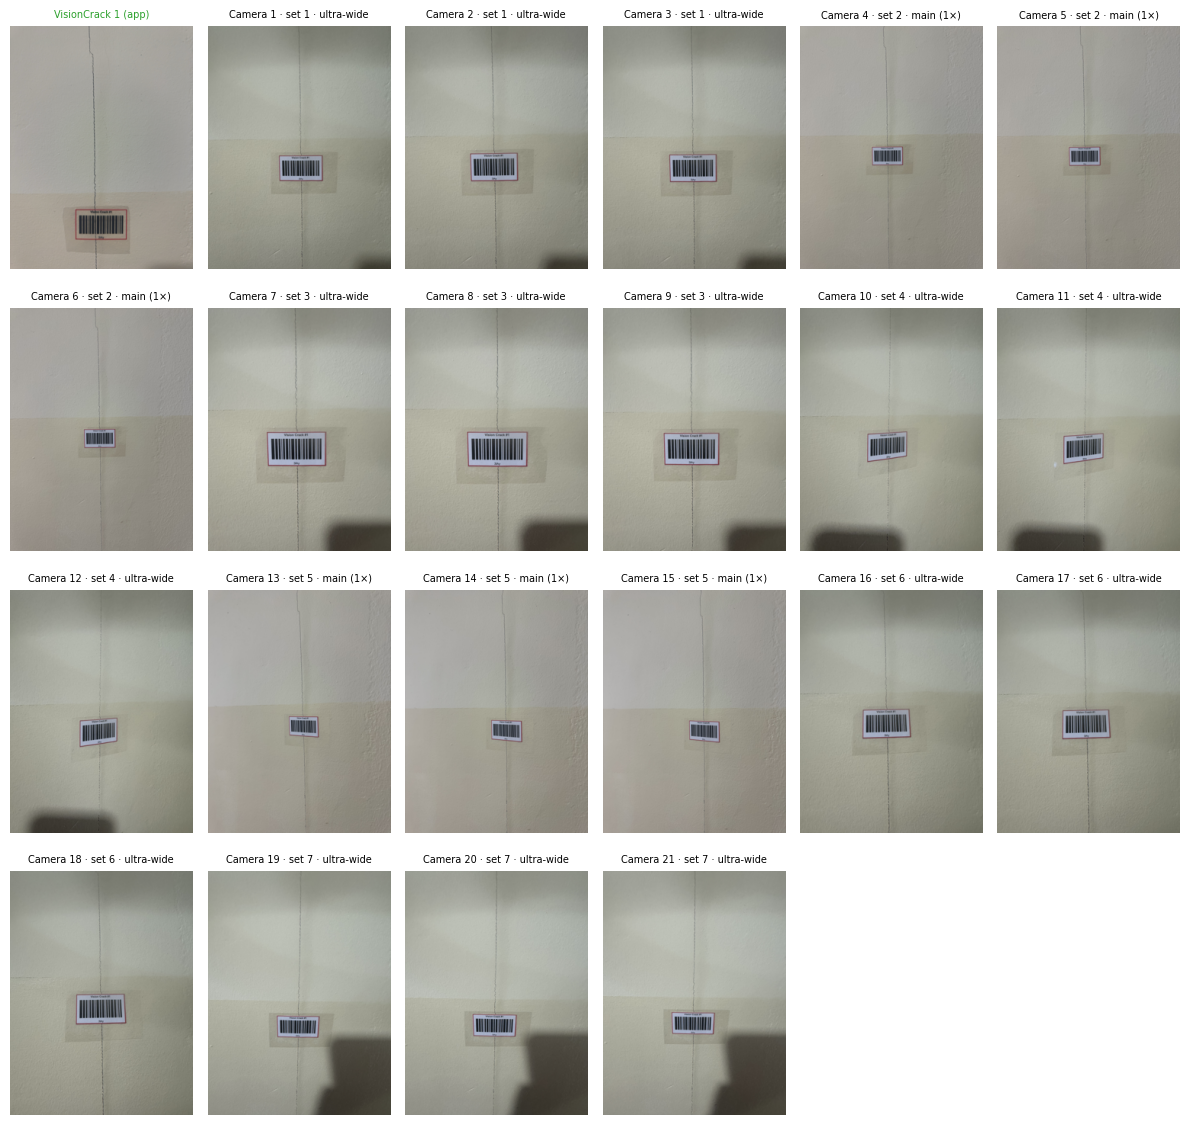

In [ ]:
fig, axs = plt.subplots(4, 6, figsize=(12, 11.5))
panels = [(app_files[0], 'VisionCrack 1 (app)', 'C2')] + \
         [(f, f'{n} · set {s} · {lens(f)}', 'k') for f, n, s in zip(cam_files, CAM, SET)]
for a in axs.ravel():
    a.axis('off')
for a, (f, title, col) in zip(axs.ravel(), panels):
    im = Image.open(f); im.thumbnail((240, 320))
    a.imshow(im); a.set_title(title, fontsize=7, color=col)
fig.tight_layout(); fig.savefig(FIG / 'camera_app_photos.png', dpi=100, bbox_inches='tight'); plt.show()

## 2 · Would the VisionCrack app have accepted these photos?

The app itself cannot be run on saved photos, so its gates are applied to the measured label:

* **distance:** label width within ±5 % of the label width in the 10 app photos (the guide-coverage rule allows about 5 %);
* **rotation:** in-plane angle below 2° (paper Step 4);
* **barcode:** the 18 bars decode to the label's code.

*Keystone* (top ÷ bottom and left ÷ right frame edges) is listed for information. It is reported only where the four frame edges come out
nearly parallel (within 1.5°); in some photos the crack crosses the frame and the corner fit fails, so the value is left empty.

In [ ]:
def keystone_pct(r, path):
    q = field.frame_corners(vc.read_rgb(path)) if r.label_found else None
    if q is None:
        return np.nan
    tl, tr, bl, br = q
    ang = lambda p, s: np.degrees(np.arctan2(s[1] - p[1], s[0] - p[0]))
    if abs(ang(tl, tr) - ang(bl, br)) > 1.5 or abs(ang(tl, bl) - ang(tr, br)) > 1.5:
        return np.nan                                   # corner fit failed
    return 100 * max(abs(r.tb_ratio - 1), abs(r.lr_ratio - 1))

W_APP = float(np.median([r.frame_w_px for r in rs_app]))
def check(r):
    if not r.label_found:
        return 'label not found'
    if abs(r.angle_deg) >= ROTATION_MAX_DEG:
        return f'rotation {abs(r.angle_deg):.1f}° ≥ 2°'
    if abs(r.frame_w_px / W_APP - 1) > 0.05:
        return f'distance: label {100 * r.frame_w_px / W_APP:.0f} % of app size'
    if not r.decode_ok:
        return 'barcode not decoded'
    return 'pass'

cap = pd.DataFrame([{
    'file': r.file, 'set': s, 'lens': lens(f), 'label_px': r.frame_w_px,
    'label_vs_app_pct': 100 * r.frame_w_px / W_APP, 'mm_per_px': r.scale,
    'angle_deg': r.angle_deg, 'keystone_pct': keystone_pct(r, f),
    'barcode': r.code if r.decode_ok else '—', 'crack_px_P3': crack_px(r), 'app_check': check(r),
} for r, f, s in zip(rs_cam, cam_files, SET)], index=CAM)
app_cap = pd.DataFrame([{'label_px': r.frame_w_px, 'mm_per_px': r.scale, 'angle_deg': r.angle_deg,
                         'keystone_pct': keystone_pct(r, f), 'crack_px_P3': crack_px(r)}
                        for r, f in zip(rs_app, app_files)], index=APP)
cap.to_csv(TAB / 'camera_app_capture.csv', float_format='%.4f')
print(f'app photos: label {app_cap.label_px.min():.0f}–{app_cap.label_px.max():.0f} px, '
      f'{app_cap.mm_per_px.mean():.4f} mm/px, |angle| ≤ {app_cap.angle_deg.abs().max():.2f}°, '
      f'keystone ≤ {app_cap.keystone_pct.max():.1f} %, crack {app_cap.crack_px_P3.mean():.1f} px at P3')
print('camera-app photos passing the app check:', (cap.app_check == 'pass').sum(), 'of', len(cap))
cap.round(3)

app photos: label 847–879 px, 0.0580 mm/px, |angle| ≤ 0.50°, keystone ≤ 1.1 %, crack 9.0 px at P3
camera-app photos passing the app check: 1 of 21


,file,set,lens,label_px,label_vs_app_pct,mm_per_px,angle_deg,keystone_pct,barcode,crack_px_P3,app_check
Camera 1,IMG_3312.png,1,ultra-wide,722.772,83.432,0.070,-0.248,2.722,3lAy,6.619,distance: label 83 % of app size
Camera 2,IMG_3313.png,1,ultra-wide,787.291,90.880,0.063,-0.618,4.134,3lAy,5.904,distance: label 91 % of app size
Camera 3,IMG_3314.png,1,ultra-wide,784.000,90.500,0.064,0.000,1.360,3lAy,6.037,distance: label 90 % of app size
Camera 4,IMG_3315.png,2,main (1×),509.383,58.800,0.098,-0.613,0.793,3lAy,3.988,distance: label 59 % of app size
Camera 5,IMG_3316.png,2,main (1×),516.697,59.644,0.096,-0.716,0.393,3lAy,4.040,distance: label 60 % of app size
Camera 6,IMG_3317.png,2,main (1×),516.123,59.578,0.096,-0.725,0.393,3lAy,3.968,distance: label 60 % of app size
Camera 7,IMG_3318.png,3,ultra-wide,981.000,113.240,0.051,0.000,NaN,3lAy,7.268,distance: label 113 % of app size
Camera 8,IMG_3319.png,3,ultra-wide,1001.008,115.550,0.050,0.283,NaN,3lAy,7.272,distance: label 116 % of app size
Camera 9,IMG_3320.png,3,ultra-wide,921.910,106.419,0.055,0.548,NaN,3lAy,7.004,distance: label 106 % of app size
Camera 10,IMG_3321.png,4,ultra-wide,NaN,NaN,NaN,NaN,NaN,—,NaN,label not found


### Mosaic: every photo in the same pixel window

Each tile is a 1300 × 1000 px window of the photo, centred on the label and **not rescaled**, so the label and crack appear at the
size the camera recorded them. The dashed green box is the label size in the app photos (the size the app's distance check
requires, ± 5 %). First three tiles: app photos. Then the seven camera-app sets, three photos each. Main-lens photos (sets 2 and 5)
show the label at about 60 % of the app's size, so the crack covers only about 4 px; the ultra-wide photos vary from 74 to 116 %.

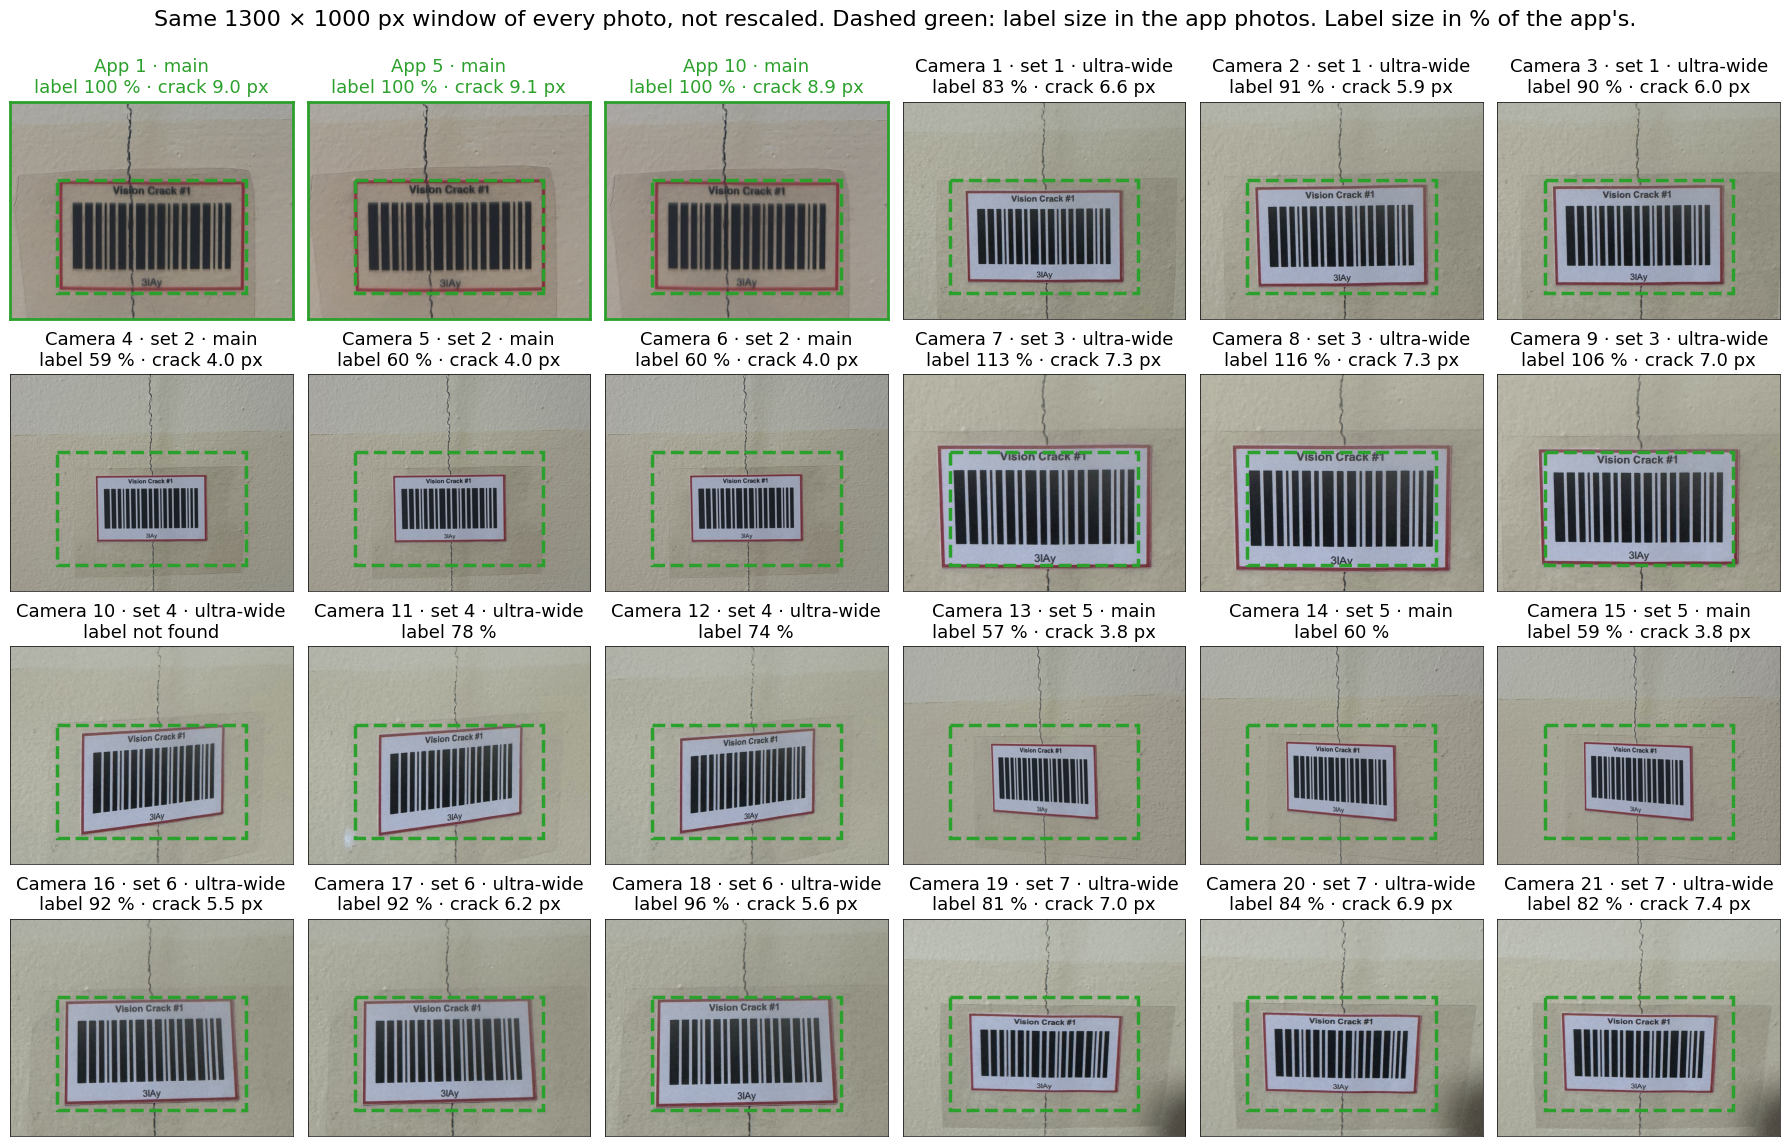

main-lens photos: label 57–60 % of app size, crack 3.8–4.0 px at P3 (app 9.0 px)
ultra-wide photos: label 74–116 % of app size


In [ ]:
WIN_W, WIN_H = 1300, 1000                          # px, same window for every photo

def window(path):
    img = vc.read_rgb(path); H_img, W_img = img.shape[:2]
    try:
        (cx, cy), _, _ = field.find_red_label(img)
    except Exception:
        cx, cy = W_img / 2, H_img / 2                 # label not found: centre of the photo
    x0, y0 = int(cx - WIN_W / 2), int(cy - 0.62 * WIN_H)  # more room above the label, where the crack is measured
    out = np.full((WIN_H, WIN_W, 3), 230, np.uint8)
    xs, ys = max(x0, 0), max(y0, 0); xe, ye = min(x0 + WIN_W, W_img), min(y0 + WIN_H, H_img)
    out[ys - y0:ye - y0, xs - x0:xe - x0] = img[ys:ye, xs:xe]
    return out, (cx - x0, cy - y0)

H_APP = W_APP * 30 / 50                              # label is 50 × 30 mm
tiles = [(app_files[k], f'App {k + 1}', 'main', 100.0, app_cap.crack_px_P3.iloc[k], 'C2') for k in (0, 4, 9)] + \
        [(f, f'Camera {i + 1} · set {s}', 'main' if lens(f).startswith('main') else 'ultra-wide', cap.label_vs_app_pct.iloc[i], cap.crack_px_P3.iloc[i], 'k')
         for i, (f, n, s) in enumerate(zip(cam_files, CAM, SET))]
fig, axs = plt.subplots(4, 6, figsize=(18, 11.6))
for a, (f, name, ln, pct, cpx, col) in zip(axs.ravel(), tiles):
    w, (u, v) = window(f)
    a.imshow(w); a.set_xticks([]); a.set_yticks([])
    a.add_patch(plt.Rectangle((u - W_APP / 2, v - H_APP / 2), W_APP, H_APP, fill=False, ec='C2', ls='--', lw=2.5))
    size = 'label not found' if not np.isfinite(pct) else f'label {pct:.0f} %'
    crack = '' if not np.isfinite(cpx) else f' · crack {cpx:.1f} px'
    a.set_title(f'{name} · {ln}\n{size}{crack}', fontsize=13, color=col)
    for sp in a.spines.values():
        sp.set_color(col); sp.set_linewidth(2 if col == 'C2' else 0.5)
fig.suptitle('Same 1300 × 1000 px window of every photo, not rescaled. Dashed green: label size in the app photos. Label size in % of the app\'s.', y=1.0, fontsize=16)
fig.tight_layout(); fig.savefig(FIG / 'camera_app_mosaic.png', dpi=110, bbox_inches='tight'); plt.show()
main = cap[cap.lens == 'main (1×)']
print(f'main-lens photos: label {main.label_vs_app_pct.min():.0f}–{main.label_vs_app_pct.max():.0f} % of app size, '
      f'crack {main.crack_px_P3.min():.1f}–{main.crack_px_P3.max():.1f} px at P3 (app {app_cap.crack_px_P3.mean():.1f} px)')
uw = cap[cap.lens == 'ultra-wide']
print(f'ultra-wide photos: label {uw.label_vs_app_pct.min():.0f}–{uw.label_vs_app_pct.max():.0f} % of app size')

## 3 · Width at the measuring point, all five options

Same code and options as notebook 12. Empty = no value (label or barcode not read, or no row passes the rule).

In [ ]:
Vt = V.copy(); Vt.insert(0, 'set', ['app'] * 10 + list(SET))
Vt.to_csv(TAB / 'camera_app_widths.csv', float_format='%.4f')
Vt.drop(columns='capture').round(3)

,set,middle row,median,mean,"Table 1 rule, > 2 px","Table 1 rule, > 6 px"
VisionCrack 1,app,0.509,0.530,0.546,0.407,0.439
VisionCrack 2,app,0.467,0.522,0.545,0.400,0.428
VisionCrack 3,app,0.537,0.524,0.547,0.404,0.429
VisionCrack 4,app,0.488,0.517,0.538,0.400,0.436
VisionCrack 5,app,0.474,0.520,0.542,0.366,0.439
VisionCrack 6,app,0.471,0.523,0.539,0.383,0.430
VisionCrack 7,app,0.508,0.526,0.546,0.365,0.406
VisionCrack 8,app,0.490,0.525,0.545,0.312,0.418
VisionCrack 9,app,0.500,0.520,0.539,0.344,0.399
VisionCrack 10,app,0.572,0.525,0.549,0.372,0.413


### Summary per option

* **measured** = photos that give a value;
* **STD** = spread over the photos (repeatability);
* **MDC** = smallest change between two photos that is larger than the spread, 1.96·√2·STD (95 %);
* **mean |error|** and **max |error|** = per photo, against GT, which is what one inspection photo would give.
  For the camera app these use the app-day GT at a different spot (§0), so read them as indicative only.

In [ ]:
rows = []
for opt in OPTIONS:
    for capname, g in V.groupby('capture', sort=False):
        v = g[opt].dropna(); e = (v - GT_MM).abs()
        rows.append({'option': opt, 'capture': capname, 'measured': f'{len(v)}/{len(g)}',
                     'mean': v.mean(), 'STD': v.std(ddof=1), 'MDC': 1.96 * np.sqrt(2) * v.std(ddof=1),
                     'min': v.min(), 'max': v.max(), '|mean − GT|': abs(v.mean() - GT_MM),
                     'mean |error|': e.mean(), 'max |error|': e.max()})
summ = pd.DataFrame(rows).set_index(['option', 'capture'])
summ.to_csv(TAB / 'camera_app_summary.csv', float_format='%.4f')
ratio = (summ.xs('camera app', level=1).STD / summ.xs('VisionCrack app', level=1).STD).rename('STD camera ÷ app')
display(summ.round(4)); ratio.round(1)

measured    mean     STD     MDC     min     max  |mean − GT|  mean |error|  max |error|
option               capture                                                                                                 
middle row           VisionCrack app    10/10  0.5016  0.0327  0.0906  0.4666  0.5721       0.0516        0.0516       0.1221
                     camera app         17/21  0.3680  0.1066  0.2953  0.2590  0.6658       0.0820        0.1131       0.2158
median               VisionCrack app    10/10  0.5230  0.0037  0.0103  0.5166  0.5298       0.0730        0.0730       0.0798
                     camera app         17/21  0.4048  0.0550  0.1525  0.3386  0.5296       0.0452        0.0661       0.1114
mean                 VisionCrack app    10/10  0.5437  0.0038  0.0106  0.5381  0.5490       0.0937        0.0937       0.0990
                     camera app         17/21  0.4292  0.0655  0.1814  0.3481  0.5652       0.0208        0.0592       0.1152
Table 1 rule, > 2 px VisionCrack app    10/10  0.3752  0.0304  0.0844  0.3118  0.4070       0.0748        0.0748       0.1382
                     camera app         17/21  0.2821  0.0708  0.1963  0.1884  0.4399       0.1679        0.1679       0.2616
Table 1 rule, > 6 px VisionCrack app    10/10  0.4237  0.0141  0.0390  0.3987  0.4393       0.0263        0.0263       0.0513
                     camera app          8/21  0.5465  0.1584  0.4390  0.3568  0.7525       0.0965        0.1387       0.3025

option
middle row               3.3
median                  14.9
mean                    17.2
Table 1 rule, > 2 px     2.3
Table 1 rule, > 6 px    11.2
Name: STD camera ÷ app, dtype: float64

### Where the spread comes from: within a set vs. between sets

Inside a set the phone is held the same way; between sets the lens, distance or angle changes.

In [ ]:
cv = V[V.capture == 'camera app'].assign(set=SET, lens=cap.lens.values, label_px=cap.label_px.values,
                                          mm_per_px=cap.mm_per_px.values, angle=cap.angle_deg.values)
sets = cv.groupby('set').agg(lens=('lens', 'first'), label_px=('label_px', 'mean'), mm_per_px=('mm_per_px', 'mean'),
                             angle=('angle', lambda a: a.abs().max()), measured=('median', 'count'),
                             median_mean=('median', 'mean'), median_sd=('median', 'std'),
                             rule6_mean=('Table 1 rule, > 6 px', 'mean'))
sets.to_csv(TAB / 'camera_app_sets.csv', float_format='%.4f')
within = np.sqrt(cv.groupby('set')['median'].var().dropna().mean())
between = sets.median_mean.dropna().std()
print(f'median option: within-set SD {within:.4f} mm · between-set SD {between:.4f} mm · '
      f'app (10 photos) SD {V.loc[APP, "median"].std():.4f} mm')
sets.round(3)

median option: within-set SD 0.0248 mm · between-set SD 0.0524 mm · app (10 photos) SD 0.0037 mm


,lens,label_px,mm_per_px,angle,measured,median_mean,median_sd,rule6_mean
set,,,,,,,,
1,ultra-wide,764.688,0.066,0.618,3,0.407,0.047,NaN
2,main (1×),514.068,0.097,0.725,3,0.387,0.004,0.724
3,ultra-wide,967.973,0.052,0.548,3,0.373,0.009,0.368
4,ultra-wide,658.764,NaN,3.883,0,NaN,NaN,NaN
5,main (1×),509.421,0.104,2.093,2,0.394,0.007,NaN
6,ultra-wide,809.000,0.062,0.000,3,0.359,0.029,0.445
7,ultra-wide,712.610,0.071,0.855,3,0.506,0.023,0.509


## 4 · Close-ups at the measuring point, same mm scale

Each panel is 3 mm wide; the band between the dashed lines is P3 (7–9 mm above the frame). The camera-app photos are drawn with their real
pixels: the farther the phone or the smaller the lens, the fewer pixels cover the crack.

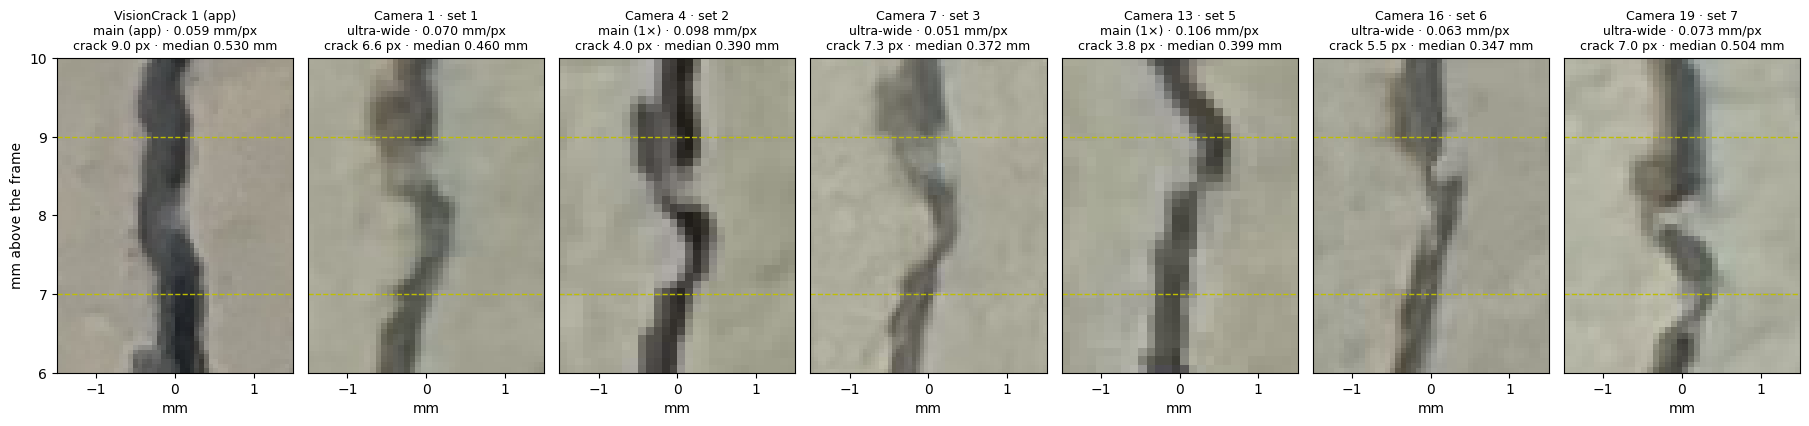

In [ ]:
def p3_crop(path, r, half_w_mm=1.5, pad_mm=1.0):
    img = vc.read_rgb(path)
    (cx, cy), (w, h), _ = field.find_red_label(img); W, H = max(w, h), min(w, h)
    rot = field.derotate(img, r.angle_deg, (cx, cy)); g = field.grey(rot); top = int(cy - H / 2)
    y0, y1 = int(top - field.BAND_MM[1] / r.scale), int(top - field.BAND_MM[0] / r.scale)
    _, xs = field.crack_widths(g, int(cx - W / 2), int(cx + W / 2), y0, y1)
    m = (r.rows_y_mm >= POINT_MM[0]) & (r.rows_y_mm < POINT_MM[1])
    xc = int(np.median(xs[m])); hw = int(half_w_mm / r.scale)
    ya, yb = int(top - (POINT_MM[1] + pad_mm) / r.scale), int(top - (POINT_MM[0] - pad_mm) / r.scale)
    return rot[ya:yb, xc - hw:xc + hw], (-half_w_mm, half_w_mm, POINT_MM[0] - pad_mm, POINT_MM[1] + pad_mm)

show = [(app_files[0], rs_app[0], 'VisionCrack 1 (app)')]
for s in sorted(set(SET)):
    k = next((i for i in np.where(SET == s)[0] if np.isfinite(V.loc[CAM[i], 'median'])), None)
    if k is not None:
        show.append((cam_files[k], rs_cam[k], f'{CAM[k]} · set {s}'))
fig, axs = plt.subplots(1, len(show), figsize=(2.6 * len(show), 5))
for a, (f, r, title) in zip(axs, show):
    crop, ext = p3_crop(f, r)
    a.imshow(crop, extent=ext, interpolation='nearest')
    for y in POINT_MM:
        a.axhline(y, color='y', ls='--', lw=1)
    n = V.loc[title.split(' ·')[0].replace(' (app)', '')]
    a.set_title(f'{title}\n{"main (app)" if "app" in title else lens(f)} · {r.scale:.3f} mm/px\ncrack {crack_px(r):.1f} px · median {n["median"]:.3f} mm',
                fontsize=9)
    a.set_xlabel('mm'); a.set_yticks([])
axs[0].set_ylabel('mm above the frame'); axs[0].set_yticks(range(6, 11))
fig.tight_layout(); fig.savefig(FIG / 'camera_app_closeups.png', dpi=130, bbox_inches='tight'); plt.show()

## 5 · Result per photo

Left: half-height median. Right: the paper's Table 1 rule (> 6 px). ✕ on the bottom axis = photo gave no value.

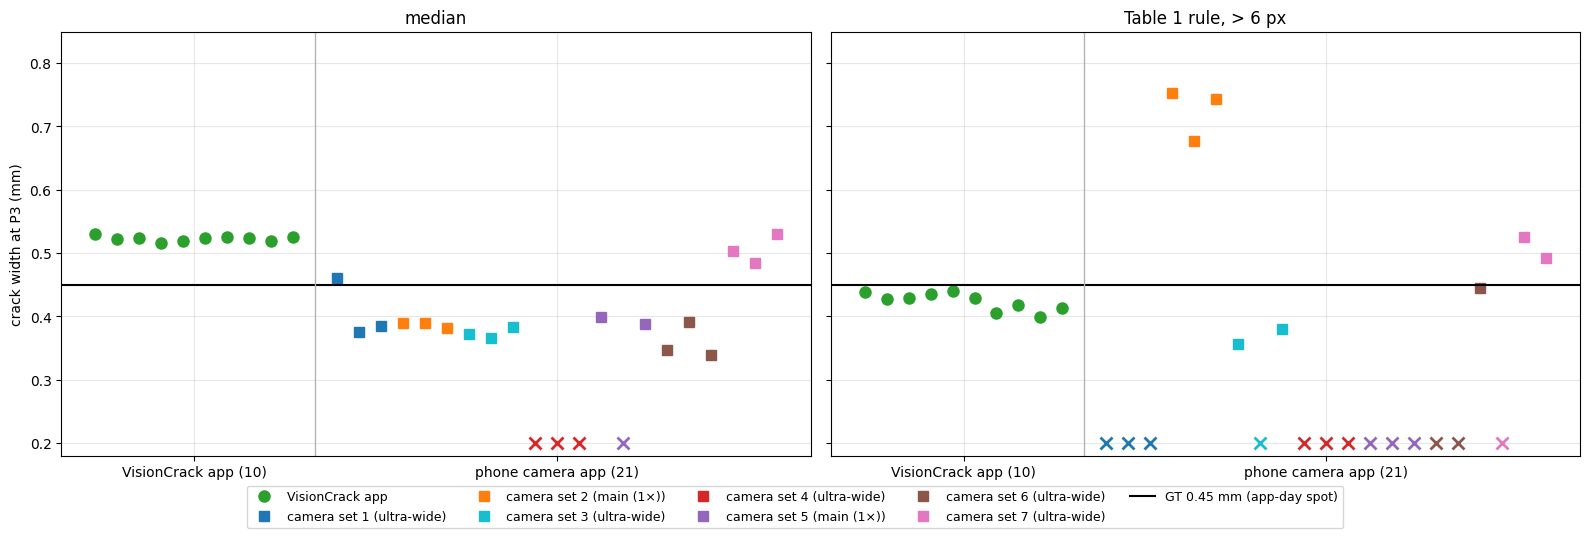

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
cols = plt.cm.tab10([0, 1, 9, 3, 4, 5, 6])      # no green: green is the app
for a, opt in zip(axs, ['median', 'Table 1 rule, > 6 px']):
    va = V.loc[APP, opt]; vcm = V.loc[CAM, opt]
    a.plot(range(1, 11), va, 'o', color='C2', ms=8, label='VisionCrack app')
    for s in range(1, 8):
        idx = np.where(SET == s)[0]; x = 12 + idx
        y = vcm.iloc[idx]
        a.plot(x[y.notna()], y[y.notna()], 's', color=cols[s - 1], ms=7, label=f'camera set {s} ({cap.lens.iloc[idx[0]]})')
        a.plot(x[y.isna()], [0.2] * y.isna().sum(), 'x', color=cols[s - 1], ms=9, mew=2)
    a.axhline(GT_MM, color='k', lw=1.5, label=f'GT {GT_MM} mm (app-day spot)')
    a.axvline(11, color='0.7', lw=1)
    a.set_title(opt); a.set_xticks([5.5, 22]); a.set_xticklabels(['VisionCrack app (10)', 'phone camera app (21)'])
    a.set_ylim(0.18, 0.85); a.grid(alpha=.3)
axs[0].set_ylabel('crack width at P3 (mm)')
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=5, fontsize=9, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout(); fig.savefig(FIG / 'camera_app_result.png', dpi=130, bbox_inches='tight'); plt.show()

## 6 · Why the camera-app photos do worse

(a) **Pixels on the crack.** The app fixes the distance, so the 0.45-mm crack always covers the same number of pixels. In the camera app it
depends on the lens and distance. With the main lens held far, the crack is only ~4–5 px wide: below the paper's 6-px noise filter, so the
Table 1 rule finds nothing, and the half-height edges sit on just a few pixels.

(b) **Lens.** Close up, the camera app switches to the ultra-wide (macro) lens on its own: a smaller sensor with stronger processing.
The app always uses the main lens.

With the main lens the 6-px filter keeps only rows where the crack reads wider than ~0.6 mm, so the few values it gives are biased up
(set 2: ≈ 0.74 mm).

(c) **Rotation.** In set 4 (3–4°) the barcode is not decoded or the label is not found, so there is no scale at all.

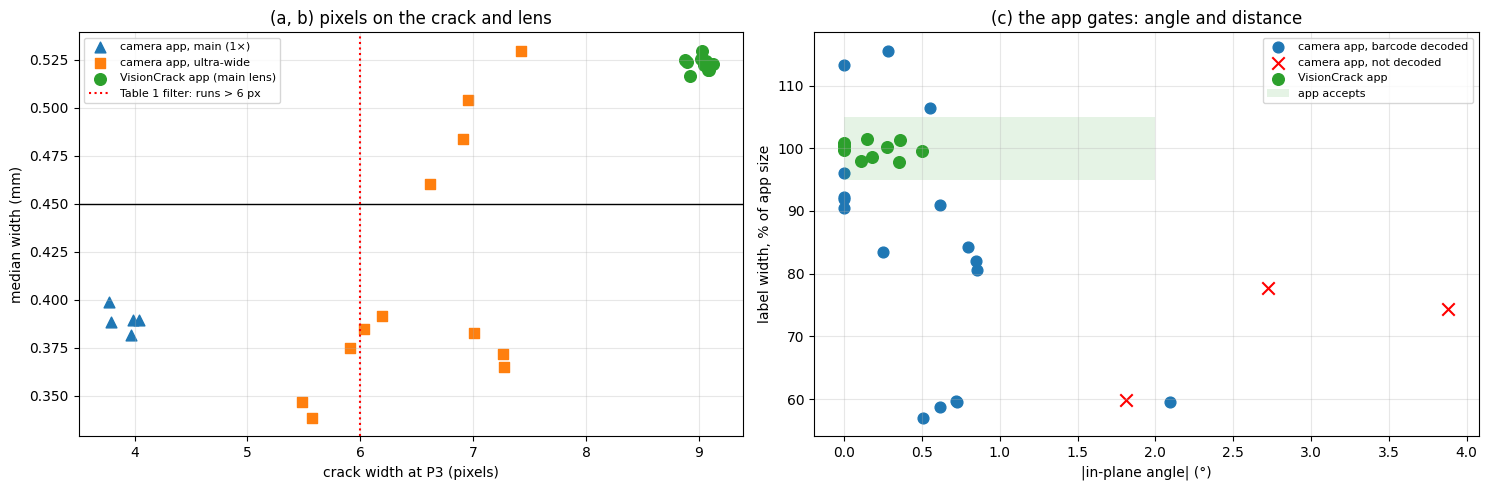

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
cm = cap.assign(median=V.loc[CAM, 'median'].values, rule6=V.loc[CAM, 'Table 1 rule, > 6 px'].values)
mk = {'ultra-wide': 's', 'main (1×)': '^'}
a = axs[0]
for ln, g in cm.groupby('lens'):
    a.scatter(g.crack_px_P3, g['median'], marker=mk[ln], s=60, label=f'camera app, {ln}')
a.scatter(app_cap.crack_px_P3, V.loc[APP, 'median'], c='C2', s=70, label='VisionCrack app (main lens)')
a.axhline(GT_MM, color='k', lw=1); a.axvline(6, color='r', ls=':', label='Table 1 filter: runs > 6 px')
a.set_xlabel('crack width at P3 (pixels)'); a.set_ylabel('median width (mm)'); a.legend(fontsize=8); a.grid(alpha=.3)
a.set_title('(a, b) pixels on the crack and lens')
a = axs[1]
ok = cm.barcode != '—'
a.scatter(cm.angle_deg.abs()[ok], cm.label_vs_app_pct[ok], c='C0', s=60, label='camera app, barcode decoded')
a.scatter(cm.angle_deg.abs()[~ok], cm.label_vs_app_pct[~ok], c='r', marker='x', s=80, label='camera app, not decoded')
a.scatter(app_cap.angle_deg.abs(), 100 * app_cap.label_px / W_APP, c='C2', s=70, label='VisionCrack app')
a.add_patch(plt.Rectangle((0, 95), 2, 10, fc='C2', alpha=.12, label='app accepts'))
a.set_xlabel('|in-plane angle| (°)'); a.set_ylabel('label width, % of app size'); a.legend(fontsize=8); a.grid(alpha=.3)
a.set_title('(c) the app gates: angle and distance')
fig.tight_layout(); fig.savefig(FIG / 'camera_app_why.png', dpi=130, bbox_inches='tight'); plt.show()

## 7 · Key numbers

In [ ]:
s = summ.round(4)
for opt in ['median', 'Table 1 rule, > 6 px']:
    a, c = s.loc[(opt, 'VisionCrack app')], s.loc[(opt, 'camera app')]
    print(f'{opt:22s} app: {a.measured} photos, STD {a.STD:.4f}, MDC {a.MDC:.3f}, max |error| {a["max |error|"]:.3f} mm | '
          f'camera: {c.measured} photos, STD {c.STD:.4f}, MDC {c.MDC:.3f}, max |error| {c["max |error|"]:.3f} mm')
print('camera-app photos the app would accept:', (cap.app_check == 'pass').sum(), '/ 21 ->',
      cap.loc[cap.app_check == 'pass', ['file', 'lens']].to_dict('records'))
print('failure reasons:', cap.app_check.str.split(':| ').str[0].value_counts().to_dict())

median                 app: 10/10 photos, STD 0.0037, MDC 0.010, max |error| 0.080 mm | camera: 17/21 photos, STD 0.0550, MDC 0.152, max |error| 0.111 mm
Table 1 rule, > 6 px   app: 10/10 photos, STD 0.0141, MDC 0.039, max |error| 0.051 mm | camera: 8/21 photos, STD 0.1584, MDC 0.439, max |error| 0.302 mm
camera-app photos the app would accept: 1 / 21 -> [{'file': 'IMG_3329.png', 'lens': 'ultra-wide'}]
failure reasons: {'distance': 16, 'rotation': 3, 'label': 1, 'pass': 1}


## 8 · Common questions

**Q1. Is the guided capture needed, or would any photo of the label do?**
Without the app the same crack and phone give widths that scatter far more from photo to photo (half-height median: STD about
15 × the app's, see §3), and the paper's rule (> 6 px) gives a value in only 8 of 21 photos. Even three photos held the same way
scatter about 7 × more than the app's ten (within-set SD, §3). The app keeps the scatter small because every photo has the same
lens, distance and angle.

**Q2. The camera-app average is close to GT with the median and mean options. Isn't it as accurate?**
First, the camera-app photos measure another spot of the crack (§0), so their GT is not known exactly. Second, even taken at face
value, the average of 17 photos taken in seven different ways landing near 0.45 mm says little about one photo: the photos range from
0.34 to 0.53 mm, and an inspector takes one photo, not 17. The app's error is a constant offset (every photo reads
about 0.07 mm wide with half-height edges, the edge offset discussed for Table 1), which can be corrected once. Random scatter cannot.
For monitoring, the smallest change the camera app can detect (MDC) is over 10 × larger than with the app.

**Q3. The comparison is unfair: the camera app used another lens.**
That is the point. The phone's camera app switches to the ultra-wide lens on its own at close range, and the user cannot see or control it.
The VisionCrack app always opens the main lens, which is one of the conditions it keeps fixed.

**Q4. Could the barcode scale correct for distance?**
Partly. The scale is measured in every photo (reference-based scaling), which is why the camera-app medians are not off by the full
change in distance. It cannot add pixels: far away the crack covers only ~4–5 px. It also cannot read a barcode rotated beyond about 2°.

**Q5. Were bad camera-app photos removed?**
No. All 21 are reported, including the four that give no value (the three of set 4 and one of set 5).

**Q6. The label is not where it was in the app photos. Does that break the comparison?**
Not the main one. The spread is measured within each set of photos at one spot, so it needs no GT, and the label did not move during the
camera-app photos. Only the error against GT is affected: 0.45 mm was read at the app-day spot. Set 7 reads ≈ 0.51 mm and the other
sets ≈ 0.36–0.41 mm *at the same spot on the same day*, so the differences come from how the phone was held, not from the crack.
To report accuracy for the camera-app photos, read the crack-width card at the new P3.

**Q7. Why is this not in the paper?**
It is a supplementary check in this repository, like notebooks 11–12. It tests the paper's main assumption (consistent capture
conditions) on a real crack.

**Q8. The photos are shared as PNG, not as the phone's HEIC files. Does that matter?**
The HEIC files were converted to PNG with ffmpeg so that they carry no EXIF or GPS data. The pixel values differ from the HEIC
decoder by at most 2 grey levels. For three camera-app photos that is enough to change the result: one barcode no longer decodes,
one more photo passes the > 6 px rule, and one reads about 1 px narrower. (The app's photos are JPEG files and were not
converted.) Results that hinge on a
grey level or two are another sign of how close the camera-app photos are to the limits of the method.
